Tune the number of layers and neurons in the network by systematically testing multiple architectures, manually tracking performance metrics, and applying advanced optimization techniques like Bayesian hyperparameter tuning.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("heart_disease_train.csv")

features = ["age", "trestbps", "chol", "thalach", "oldpeak"]
target = "target"

df = df[features + [target]].dropna()

X = df[features].astype(float).to_numpy()
y = df[target].astype(int).to_numpy()

print("Dataset shape:", df.shape)
print("Features:", features)
print("Classes:", np.unique(y))

Dataset shape: (79, 6)
Features: ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
Classes: [0 1]


In [2]:
np.random.seed(42)

indices = np.random.permutation(len(X))
n = len(X)

train_end = int(0.70 * n)
val_end = int(0.85 * n)

train_idx = indices[:train_end]
val_idx = indices[train_end:val_end]
test_idx = indices[val_end:]

X_train_raw, y_train = X[train_idx], y[train_idx]
X_val_raw, y_val = X[val_idx], y[val_idx]
X_test_raw, y_test = X[test_idx], y[test_idx]

mean = X_train_raw.mean(axis=0)
std = X_train_raw.std(axis=0)
std[std == 0] = 1

X_train = (X_train_raw - mean) / std
X_val = (X_val_raw - mean) / std
X_test = (X_test_raw - mean) / std

print("Training records:", len(X_train))
print("Validation records:", len(X_val))
print("Testing records:", len(X_test))

Training records: 55
Validation records: 12
Testing records: 12


In [3]:
def train_network(X, y, architecture, learning_rate=0.01, epochs=150):
    np.random.seed(42)

    y = y.reshape(-1, 1)
    sizes = [X.shape[1]] + list(architecture) + [1]

    weights = []
    biases = []

    for i in range(len(sizes) - 1):
        weights.append(
            np.random.randn(sizes[i], sizes[i + 1])
            * np.sqrt(2 / sizes[i])
        )
        biases.append(np.zeros((1, sizes[i + 1])))

    for epoch in range(epochs):
        activations = [X]
        pre_activations = []

        for i in range(len(weights) - 1):
            z = activations[-1] @ weights[i] + biases[i]
            pre_activations.append(z)
            activations.append(np.maximum(0, z))

        z_out = activations[-1] @ weights[-1] + biases[-1]
        z_out = np.clip(z_out, -30, 30)
        output = 1 / (1 + np.exp(-z_out))
        pre_activations.append(z_out)
        activations.append(output)

        delta = (output - y) / len(y)

        for i in reversed(range(len(weights))):
            dw = activations[i + (0 if i == len(weights) - 1 else 1)].T @ delta if False else None

            if i == len(weights) - 1:
                previous_activation = activations[i]
            else:
                previous_activation = activations[i + 1]

            dw = previous_activation.T @ delta
            db = np.sum(delta, axis=0, keepdims=True)

            if i > 0:
                delta = (delta @ weights[i].T) * (
                    pre_activations[i - 1] > 0
                )

            weights[i] -= learning_rate * dw
            biases[i] -= learning_rate * db

    return weights, biases


def predict_network(X, model):
    weights, biases = model
    activation = X

    for i in range(len(weights) - 1):
        activation = np.maximum(0, activation @ weights[i] + biases[i])

    z = np.clip(activation @ weights[-1] + biases[-1], -30, 30)
    probabilities = 1 / (1 + np.exp(-z))

    return probabilities.ravel()

In [4]:
def train_network(X, y, architecture, learning_rate=0.01, epochs=150):
    np.random.seed(42)

    y = y.reshape(-1, 1)
    sizes = [X.shape[1]] + list(architecture) + [1]

    weights = []
    biases = []

    for i in range(len(sizes) - 1):
        weights.append(
            np.random.randn(sizes[i], sizes[i + 1])
            * np.sqrt(2 / sizes[i])
        )
        biases.append(np.zeros((1, sizes[i + 1])))

    for epoch in range(epochs):
        activations = [X]
        pre_activations = []

        for i in range(len(weights) - 1):
            z = activations[-1] @ weights[i] + biases[i]
            pre_activations.append(z)
            activations.append(np.maximum(0, z))

        z = activations[-1] @ weights[-1] + biases[-1]
        z = np.clip(z, -30, 30)
        output = 1 / (1 + np.exp(-z))

        delta = (output - y) / len(y)

        for i in reversed(range(len(weights))):
            dw = activations[i].T @ delta
            db = np.sum(delta, axis=0, keepdims=True)

            if i > 0:
                delta = (delta @ weights[i].T) * (
                    pre_activations[i - 1] > 0
                )

            weights[i] -= learning_rate * dw
            biases[i] -= learning_rate * db

    return weights, biases


def predict_network(X, model):
    weights, biases = model
    activation = X

    for i in range(len(weights) - 1):
        activation = np.maximum(
            0, activation @ weights[i] + biases[i]
        )

    z = np.clip(activation @ weights[-1] + biases[-1], -30, 30)
    return (1 / (1 + np.exp(-z))).ravel()

In [5]:
architectures = [
    (8,),
    (16,),
    (32,),
    (8, 8),
    (16, 16),
    (32, 16),
    (16, 8),
    (8, 8, 8),
    (16, 16, 16),
    (32, 16, 8),
    (32, 32),
    (16, 8, 8)
]

learning_rates = [0.001, 0.01, 0.05]

print("Architecture candidates:", len(architectures))
print("Learning rate options:", learning_rates)

Architecture candidates: 12
Learning rate options: [0.001, 0.01, 0.05]


In [6]:
def evaluate_network(y_true, probabilities):
    predictions = (probabilities >= 0.5).astype(int)
    accuracy = np.mean(predictions == y_true) * 100

    p = np.clip(probabilities, 1e-8, 1 - 1e-8)
    loss = -np.mean(
        y_true * np.log(p) + (1 - y_true) * np.log(1 - p)
    )

    return accuracy, loss


results = []

for architecture in architectures:
    for rate in learning_rates:
        model = train_network(
            X_train, y_train, architecture,
            learning_rate=rate, epochs=150
        )

        probabilities = predict_network(X_val, model)
        accuracy, loss = evaluate_network(y_val, probabilities)

        results.append({
            "Architecture": str(architecture),
            "Layers": len(architecture),
            "Neurons": sum(architecture),
            "Learning Rate": rate,
            "Validation Accuracy": accuracy,
            "Validation Loss": loss
        })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    "Validation Loss"
).reset_index(drop=True)

print(results_df.round(4).to_string(index=False))

Architecture  Layers  Neurons  Learning Rate  Validation Accuracy  Validation Loss
    (32, 16)       2       48          0.050             100.0000           0.1673
  (16, 8, 8)       3       32          0.050             100.0000           0.1840
    (32, 32)       2       64          0.050              91.6667           0.2015
       (32,)       1       32          0.050             100.0000           0.2039
    (16, 16)       2       32          0.050              91.6667           0.2294
       (16,)       1       16          0.050              91.6667           0.2388
     (16, 8)       2       24          0.050              83.3333           0.2468
   (8, 8, 8)       3       24          0.050              83.3333           0.2593
 (32, 16, 8)       3       56          0.050              83.3333           0.2824
      (8, 8)       2       16          0.050              91.6667           0.2839
(16, 16, 16)       3       48          0.050              83.3333           0.2984
    

In [7]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, WhiteKernel
from scipy.stats import norm
import itertools

candidates = list(itertools.product(
    range(len(architectures)),
    learning_rates
))

def run_trial(architecture_index, rate):
    architecture = architectures[architecture_index]

    model = train_network(
        X_train, y_train, architecture,
        learning_rate=rate, epochs=150
    )

    probabilities = predict_network(X_val, model)
    accuracy, loss = evaluate_network(y_val, probabilities)

    return {
        "Architecture": str(architecture),
        "Layers": len(architecture),
        "Neurons": sum(architecture),
        "Learning Rate": rate,
        "Validation Accuracy": accuracy,
        "Validation Loss": loss,
        "architecture_index": architecture_index
    }


def encode_candidate(candidate):
    arch_index, rate = candidate
    return [arch_index / max(len(architectures) - 1, 1),
            np.log10(rate)]


np.random.seed(42)
initial_indices = np.random.choice(
    len(candidates), size=5, replace=False
)

tested = [candidates[i] for i in initial_indices]
bayes_results = [
    run_trial(i, rate) for i, rate in tested
]

for step in range(5):
    X_observed = np.array([encode_candidate(c) for c in tested])
    y_observed = np.array([
        r["Validation Loss"] for r in bayes_results
    ])

    gp = GaussianProcessRegressor(
        kernel=Matern(nu=2.5) + WhiteKernel(noise_level=1e-5),
        normalize_y=True,
        n_restarts_optimizer=2,
        random_state=42
    )

    gp.fit(X_observed, y_observed)

    remaining = [c for c in candidates if c not in tested]

    if not remaining:
        break

    X_remaining = np.array([encode_candidate(c) for c in remaining])
    mu, sigma = gp.predict(X_remaining, return_std=True)

    best_loss = min(y_observed)
    improvement = best_loss - mu - 0.01
    z = improvement / np.maximum(sigma, 1e-9)

    expected_improvement = (
        improvement * norm.cdf(z)
        + sigma * norm.pdf(z)
    )

    next_candidate = remaining[int(np.argmax(expected_improvement))]
    tested.append(next_candidate)

    result = run_trial(*next_candidate)
    bayes_results.append(result)

    print(
        "Bayesian trial", step + 1,
        "| Architecture:", result["Architecture"],
        "| Learning rate:", result["Learning Rate"],
        "| Validation loss:", round(result["Validation Loss"], 4)
    )

results_df = pd.DataFrame(bayes_results).sort_values(
    "Validation Loss"
).reset_index(drop=True)

print("\nBayesian Search Results")
print(results_df.drop(columns=["architecture_index"]).round(4).to_string(index=False))

Bayesian trial 1 | Architecture: (32, 16, 8) | Learning rate: 0.01 | Validation loss: 0.5172
Bayesian trial 2 | Architecture: (32, 32) | Learning rate: 0.05 | Validation loss: 0.2015


c:\Users\Lenovo\AppData\Local\Python\pythoncore-3.13-64\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\Lenovo\AppData\Local\Python\pythoncore-3.13-64\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


Bayesian trial 3 | Architecture: (8,) | Learning rate: 0.05 | Validation loss: 0.3065
Bayesian trial 4 | Architecture: (8,) | Learning rate: 0.001 | Validation loss: 0.751
Bayesian trial 5 | Architecture: (8, 8) | Learning rate: 0.05 | Validation loss: 0.2839

Bayesian Search Results
Architecture  Layers  Neurons  Learning Rate  Validation Accuracy  Validation Loss
  (16, 8, 8)       3       32          0.050             100.0000           0.1840
    (32, 32)       2       64          0.050              91.6667           0.2015
      (8, 8)       2       16          0.050              91.6667           0.2839
(16, 16, 16)       3       48          0.050              83.3333           0.2984
        (8,)       1        8          0.050              91.6667           0.3065
    (32, 16)       2       48          0.010             100.0000           0.3574
    (16, 16)       2       32          0.010              83.3333           0.4382
 (32, 16, 8)       3       56          0.010       

c:\Users\Lenovo\AppData\Local\Python\pythoncore-3.13-64\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\Lenovo\AppData\Local\Python\pythoncore-3.13-64\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


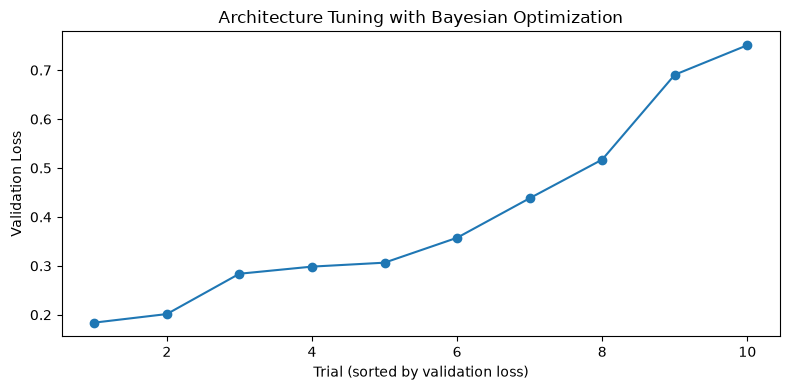

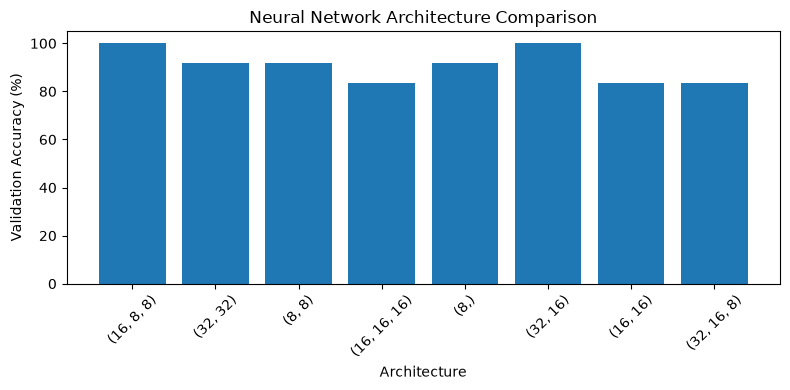

In [8]:
plt.figure(figsize=(8, 4))
plt.plot(
    range(1, len(results_df) + 1),
    results_df["Validation Loss"],
    marker="o"
)
plt.xlabel("Trial (sorted by validation loss)")
plt.ylabel("Validation Loss")
plt.title("Architecture Tuning with Bayesian Optimization")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
plt.bar(
    results_df["Architecture"],
    results_df["Validation Accuracy"]
)
plt.xlabel("Architecture")
plt.ylabel("Validation Accuracy (%)")
plt.title("Neural Network Architecture Comparison")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [9]:
best_row = results_df.iloc[0]
best_architecture = architectures[int(best_row["architecture_index"])]
best_rate = float(best_row["Learning Rate"])

final_model = train_network(
    X_train, y_train,
    best_architecture,
    learning_rate=best_rate,
    epochs=150
)

test_probabilities = predict_network(X_test, final_model)
test_predictions = (test_probabilities >= 0.5).astype(int)

tp = np.sum((y_test == 1) & (test_predictions == 1))
tn = np.sum((y_test == 0) & (test_predictions == 0))
fp = np.sum((y_test == 0) & (test_predictions == 1))
fn = np.sum((y_test == 1) & (test_predictions == 0))

accuracy = (tp + tn) / len(y_test) * 100
precision = tp / (tp + fp) if tp + fp else 0
recall = tp / (tp + fn) if tp + fn else 0
f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0

print("Best Architecture:", best_architecture)
print("Best Learning Rate:", best_rate)
print("Test Accuracy:", round(accuracy, 2), "%")
print("Test Precision:", round(precision * 100, 2), "%")
print("Test Recall:", round(recall * 100, 2), "%")
print("Test F1-Score:", round(f1 * 100, 2), "%")

Best Architecture: (16, 8, 8)
Best Learning Rate: 0.05
Test Accuracy: 91.67 %
Test Precision: 90.91 %
Test Recall: 100.0 %
Test F1-Score: 95.24 %
